# Customer Churn Prediction – NTI Final Project

## Part 1 - Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("Cell2Cell.csv")
print("Shape:", df.shape)
df.head()

Shape: (51047, 58)


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,0.7,0.7,6.3,0.0,0.0,97.2,0.0,0.0,58.0,24.0,1.3,0.0,0.3,61,2,1,SEAPOR503,2.0,2.0,361.0,62.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,Yes,Yes,1,0,No,No,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,0.3,0.0,2.7,0.0,0.0,0.0,0.0,0.0,5.0,1.0,0.3,0.0,0.0,58,1,1,PITHOM412,2.0,1.0,1504.0,40.0,42.0,Yes,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,Yes,No,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.4,0.3,0.0,1.3,3.7,0.0,0.0,0.0,60,1,1,MILMIL414,1.0,1.0,1812.0,26.0,26.0,Yes,No,No,No,No,Unknown,No,No,No,No,No,Yes,0,0,Yes,No,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,52.0,7.7,76.0,4.3,1.3,200.3,370.3,147.0,555.7,303.7,59.7,0.0,22.7,59,2,2,PITHOM412,9.0,4.0,458.0,30.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,Yes,No,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,53,2,2,OKCTUL918,4.0,3.0,852.0,46.0,54.0,No,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,No,Yes,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


In [3]:
df.tail()

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
51042,3399958,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.3,2.7,48.3,0.0,0.0,58.9,17.0,1.3,160.3,33.3,12.0,0.0,0.3,29,1,1,LAXSFN818,2.0,2.0,526.0,68.0,64.0,No,Yes,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,No,No,0,6,No,0,60,No,1-Highest,Suburban,Other,Yes
51043,3399974,No,95.17,1745.0,85.0,0.99,45.0,4.7,122.0,15.9,16.7,0.7,41.3,0.0,0.0,681.5,89.7,33.3,318.7,248.3,17.3,0.0,14.3,29,1,1,LAXCDG310,2.0,2.0,464.0,48.0,48.0,Yes,No,Yes,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,No,No,0,9,No,1,60,No,3-Good,Other,Other,No
51044,3399978,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,71.7,4.3,287.0,1.3,13.7,1225.3,430.3,87.7,1359.0,910.3,76.0,0.0,6.7,25,1,1,LAXCDG310,3.0,2.0,378.0,36.0,0.0,No,No,Yes,No,No,Known,No,No,No,No,No,Yes,0,0,No,No,0,7,No,1,80,No,5-Low,Other,Clerical,No
51045,3399990,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31,1,1,NEVPOW619,2.0,2.0,433.0,32.0,0.0,Yes,No,Yes,No,No,Unknown,No,No,No,No,No,No,0,0,No,No,0,9,No,0,30,No,5-Low,Other,Other,No
51046,3399994,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.7,0.7,117.3,1.3,1.0,330.9,55.0,16.7,442.3,167.3,19.3,0.0,0.0,25,1,1,NEVPOW619,7.0,5.0,75.0,0.0,0.0,No,No,Yes,No,No,Unknown,No,No,No,No,No,No,2,1,No,No,0,0,No,1,60,Yes,5-Low,Other,Other,Unknown


## Part 2 - Data Understanding

In [4]:
print('Dataset shape:', df.shape)

Dataset shape: (51047, 58)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51047 entries, 0 to 51046
Data columns (total 58 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 51047 non-null  int64  
 1   Churn                      51047 non-null  object 
 2   MonthlyRevenue             50891 non-null  float64
 3   MonthlyMinutes             50891 non-null  float64
 4   TotalRecurringCharge       50891 non-null  float64
 5   DirectorAssistedCalls      50891 non-null  float64
 6   OverageMinutes             50891 non-null  float64
 7   RoamingCalls               50891 non-null  float64
 8   PercChangeMinutes          50680 non-null  float64
 9   PercChangeRevenues         50680 non-null  float64
 10  DroppedCalls               51047 non-null  float64
 11  BlockedCalls               51047 non-null  float64
 12  UnansweredCalls            51047 non-null  float64
 13  CustomerCareCalls          51047 non-null  flo

In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,51047.0,NaN,NaN,NaN,3201956.877818,116905.561666,3000002.0,3100632.0,3201534.0,3305376.0,3399994.0
Churn,51047,2,No,36336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthlyRevenue,50891.0,NaN,NaN,NaN,58.834492,44.507336,-6.17,33.61,48.46,71.065,1223.38
MonthlyMinutes,50891.0,NaN,NaN,NaN,525.653416,529.871063,0.0,158.0,366.0,723.0,7359.0
TotalRecurringCharge,50891.0,NaN,NaN,NaN,46.830088,23.848871,-11.0,30.0,45.0,60.0,400.0
DirectorAssistedCalls,50891.0,NaN,NaN,NaN,0.895229,2.228546,0.0,0.0,0.25,0.99,159.39
OverageMinutes,50891.0,NaN,NaN,NaN,40.027785,96.588076,0.0,0.0,3.0,41.0,4321.0
RoamingCalls,50891.0,NaN,NaN,NaN,1.236244,9.818294,0.0,0.0,0.0,0.3,1112.4
PercChangeMinutes,50680.0,NaN,NaN,NaN,-11.547908,257.514772,-3875.0,-83.0,-5.0,66.0,5192.0
PercChangeRevenues,50680.0,NaN,NaN,NaN,-1.191985,39.574915,-1107.7,-7.1,-0.3,1.6,2483.5


In [7]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

CustomerID: 51047 unique values
Churn: 2 unique values
MonthlyRevenue: 12665 unique values
MonthlyMinutes: 2719 unique values
TotalRecurringCharge: 214 unique values
DirectorAssistedCalls: 146 unique values
OverageMinutes: 746 unique values
RoamingCalls: 530 unique values
PercChangeMinutes: 2262 unique values
PercChangeRevenues: 2899 unique values
DroppedCalls: 285 unique values
BlockedCalls: 373 unique values
UnansweredCalls: 840 unique values
CustomerCareCalls: 185 unique values
ThreewayCalls: 78 unique values
ReceivedCalls: 6121 unique values
OutboundCalls: 787 unique values
InboundCalls: 472 unique values
PeakCallsInOut: 1839 unique values
OffPeakCallsInOut: 1669 unique values
DroppedBlockedCalls: 447 unique values
CallForwardingCalls: 31 unique values
CallWaitingCalls: 223 unique values
MonthsInService: 56 unique values
UniqueSubs: 15 unique values
ActiveSubs: 12 unique values
ServiceArea: 747 unique values
Handsets: 23 unique values
HandsetModels: 13 unique values
CurrentEquipmen

In [8]:
# Identify numerical and categorical features (excluding target and customer ID)

feature_data = df.drop(columns=["Churn", "CustomerID"], errors="ignore")

numeric_cols_info = feature_data.select_dtypes(include=np.number).columns.tolist()
categorical_cols_info = feature_data.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of Numerical Features:", len(numeric_cols_info))
print("Number of Categorical Features:", len(categorical_cols_info))

print("\nNumerical Features:")
print(numeric_cols_info)

print("\nCategorical Features:")
print(categorical_cols_info)

Number of Numerical Features: 34
Number of Categorical Features: 22

Numerical Features:
['MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'RetentionCalls', 'RetentionOffersAccepted', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'AdjustmentsToCreditRating']

Categorical Features:
['ServiceArea', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'NewCellphoneUse

## Part 3 - Data Cleaning

In [9]:
# Create a separate copy for cleaning and EDA
df_clean = df.copy()

print("Initial shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing values:", df_clean.isnull().sum().sum())

Initial shape: (51047, 58)
Duplicate rows: 0
Missing values: 3515


In [10]:
# Remove duplicate rows if any exist
duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()

print("Duplicate rows before:", duplicates_before)
print("Duplicate rows after:", df_clean.duplicated().sum())
print("Shape after duplicate check:", df_clean.shape)

Duplicate rows before: 0
Duplicate rows after: 0
Shape after duplicate check: (51047, 58)


In [11]:
# Identify numerical columns
numerical_features = df_clean.select_dtypes(include=np.number).columns.tolist()

print("Number of numerical columns:", len(numerical_features))
print(numerical_features)

Number of numerical columns: 35
['CustomerID', 'MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'RetentionCalls', 'RetentionOffersAccepted', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'AdjustmentsToCreditRating']


In [12]:
# Detect outliers using the IQR method (report only; do not automatically delete)
outliers_summary = []

for col in numerical_features:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()

    outliers_summary.append({
        "Feature": col,
        "Outliers Count": outliers,
        "Outliers Percentage": round(outliers / len(df_clean) * 100, 2),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2)
    })

outliers_df = pd.DataFrame(outliers_summary).sort_values(
    by="Outliers Percentage", ascending=False
)
display(outliers_df)

,Feature,Outliers Count,Outliers Percentage,Lower Bound,Upper Bound
8,PercChangeRevenues,13221,25.90,-20.15,14.65
6,RoamingCalls,8835,17.31,-0.45,0.75
21,CallWaitingCalls,7448,14.59,-1.95,3.25
7,PercChangeMinutes,6807,13.33,-306.50,289.50
12,CustomerCareCalls,6721,13.17,-2.55,4.25
5,OverageMinutes,5842,11.44,-61.50,102.50
4,DirectorAssistedCalls,5530,10.83,-1.48,2.47
10,BlockedCalls,5517,10.81,-5.55,9.25
16,InboundCalls,4973,9.74,-13.95,23.25
13,ThreewayCalls,4622,9.05,-0.45,0.75


In [13]:
# Review missing values before imputation
missing_values = df_clean.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Missing Values:")
print(missing_values)
print("\nTotal Missing Values:", missing_values.sum())

Missing Values:
AgeHH2                   909
AgeHH1                   909
PercChangeRevenues       367
PercChangeMinutes        367
MonthlyRevenue           156
MonthlyMinutes           156
RoamingCalls             156
OverageMinutes           156
DirectorAssistedCalls    156
TotalRecurringCharge     156
ServiceArea               24
Handsets                   1
CurrentEquipmentDays       1
HandsetModels              1
dtype: int64

Total Missing Values: 3515


In [14]:
# Check negative values in numerical columns
numerical_cols = df_clean.select_dtypes(include=np.number).columns
negative_counts = (df_clean[numerical_cols] < 0).sum()
negative_counts = negative_counts[negative_counts > 0].sort_values(ascending=False)

print("Negative Values:")
print(negative_counts)

Negative Values:
PercChangeRevenues      28408
PercChangeMinutes       26816
CurrentEquipmentDays       76
TotalRecurringCharge        8
MonthlyRevenue              3
dtype: int64


In [15]:
# Inspect negative values in selected columns before deciding how to handle them
columns_to_check = [
    "CurrentEquipmentDays",
    "TotalRecurringCharge",
    "MonthlyRevenue"
]

for col in columns_to_check:
    print(f"\n{col}")
    print("Minimum:", df_clean[col].min())
    print("Maximum:", df_clean[col].max())
    print("Negative values:")
    print(df_clean.loc[df_clean[col] < 0, col].value_counts().sort_index())


CurrentEquipmentDays
Minimum: -5.0
Maximum: 1812.0
Negative values:
CurrentEquipmentDays
-5.0     3
-4.0     6
-3.0    26
-2.0    23
-1.0    18
Name: count, dtype: int64

TotalRecurringCharge
Minimum: -11.0
Maximum: 400.0
Negative values:
TotalRecurringCharge
-11.0    1
-9.0     1
-6.0     2
-5.0     1
-2.0     2
-1.0     1
Name: count, dtype: int64

MonthlyRevenue
Minimum: -6.17
Maximum: 1223.38
Negative values:
MonthlyRevenue
-6.17    1
-5.86    1
-2.52    1
Name: count, dtype: int64


In [16]:
# Treat negative values in these three fields as invalid/missing for this project.
# Negative percentage changes are retained because they can represent real decreases.
columns_to_fix = [
    "CurrentEquipmentDays",
    "TotalRecurringCharge",
    "MonthlyRevenue"
]

for col in columns_to_fix:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

print("Negative values after handling:")
for col in columns_to_fix:
    print(f"{col}: {(df_clean[col] < 0).sum()}")

print("\nMissing values after handling:", df_clean.isnull().sum().sum())

Negative values after handling:
CurrentEquipmentDays: 0
TotalRecurringCharge: 0
MonthlyRevenue: 0

Missing values after handling: 3602


In [17]:
# Impute missing values in the EDA copy only.
# For model training, imputation will be fitted inside a Pipeline after the train-test split.
numerical_cols = df_clean.select_dtypes(include=np.number).columns
categorical_cols = df_clean.select_dtypes(include="object").columns

for col in numerical_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in categorical_cols:
    if df_clean[col].isnull().any():
        mode_values = df_clean[col].mode()
        if not mode_values.empty:
            df_clean[col] = df_clean[col].fillna(mode_values[0])

print("Missing values after EDA imputation:", df_clean.isnull().sum().sum())

Missing values after EDA imputation: 0


In [18]:
# Final cleaning validation
print("Cleaned dataset shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing values:", df_clean.isnull().sum().sum())
print("\nData types:")
print(df_clean.dtypes.value_counts())

Cleaned dataset shape: (51047, 58)
Duplicate rows: 0
Missing values: 0

Data types:
float64    26
object     23
int64       9
Name: count, dtype: int64


## Part 4 - Exploratory Data Analysis (EDA)

In [19]:
print("Target Variable Distribution:")
print(df_clean["Churn"].value_counts())

print("\nTarget Variable Percentage:")
print((df_clean["Churn"].value_counts(normalize=True) * 100).round(2))

Target Variable Distribution:
Churn
No     36336
Yes    14711
Name: count, dtype: int64

Target Variable Percentage:
Churn
No     71.18
Yes    28.82
Name: proportion, dtype: float64


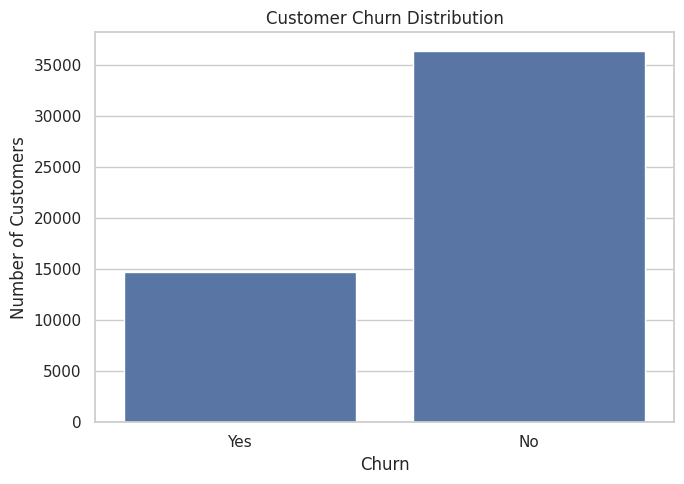

In [20]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

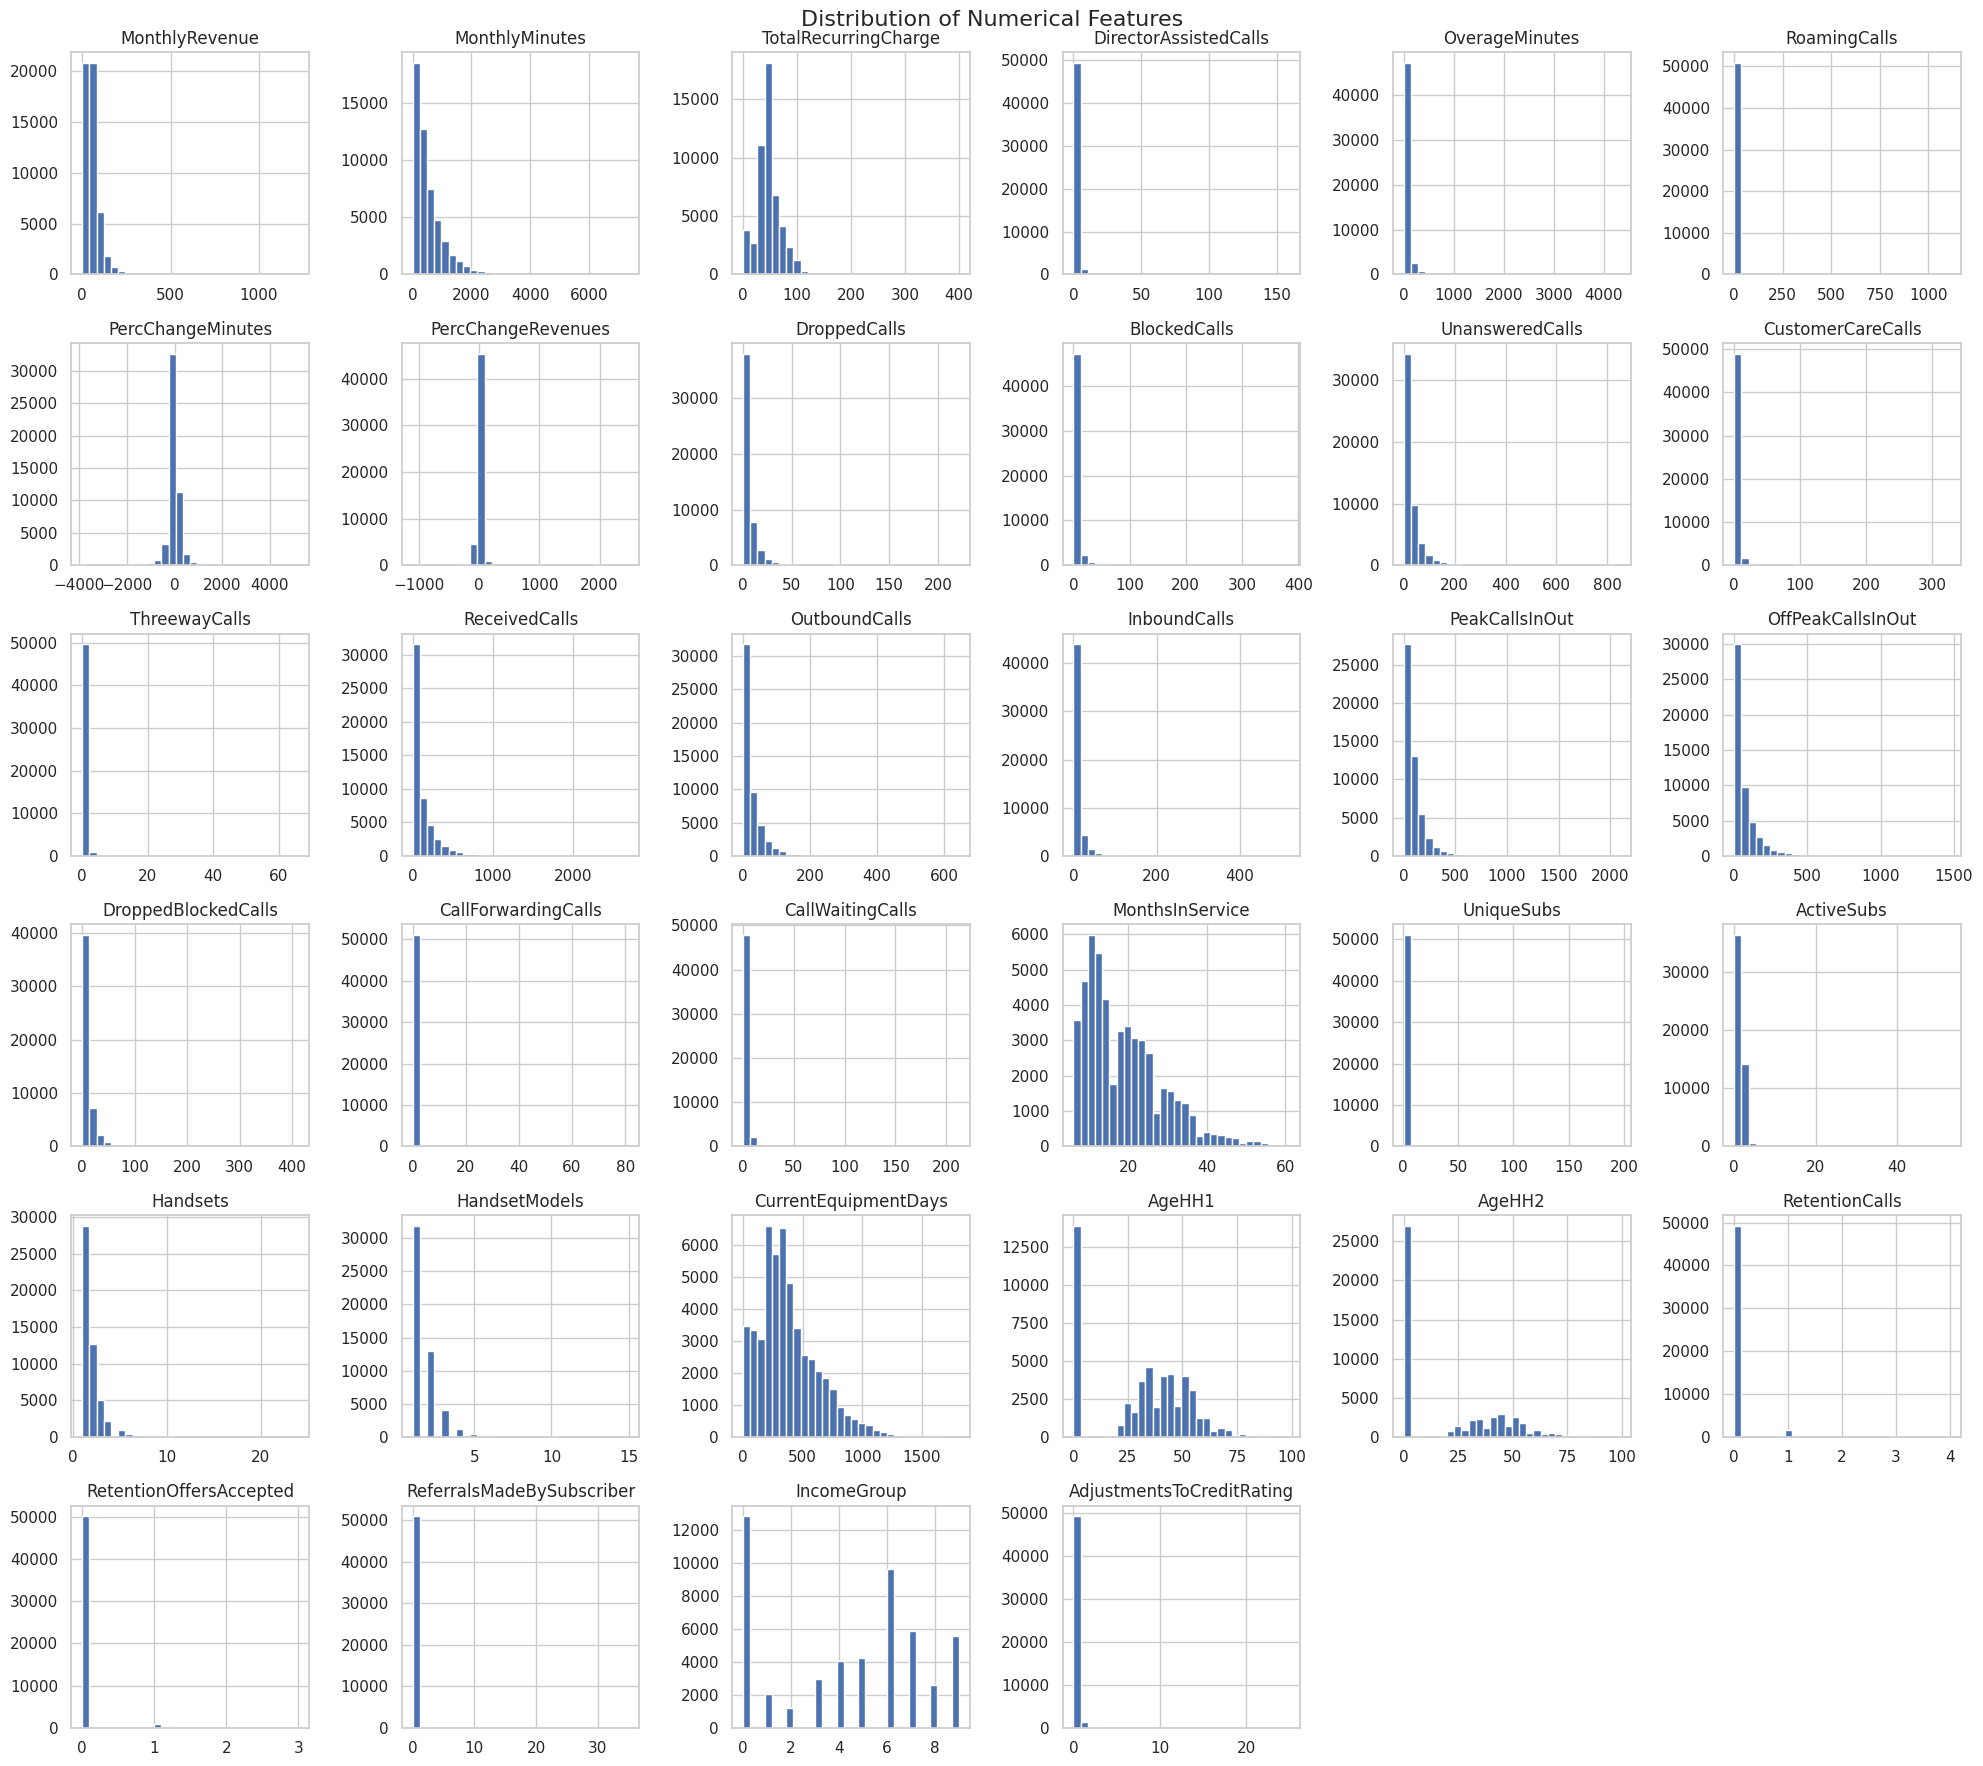

In [21]:
numerical_features = df_clean.select_dtypes(include=np.number).columns.drop(
    "CustomerID", errors="ignore"
)

df_clean[numerical_features].hist(figsize=(20, 18), bins=30)
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

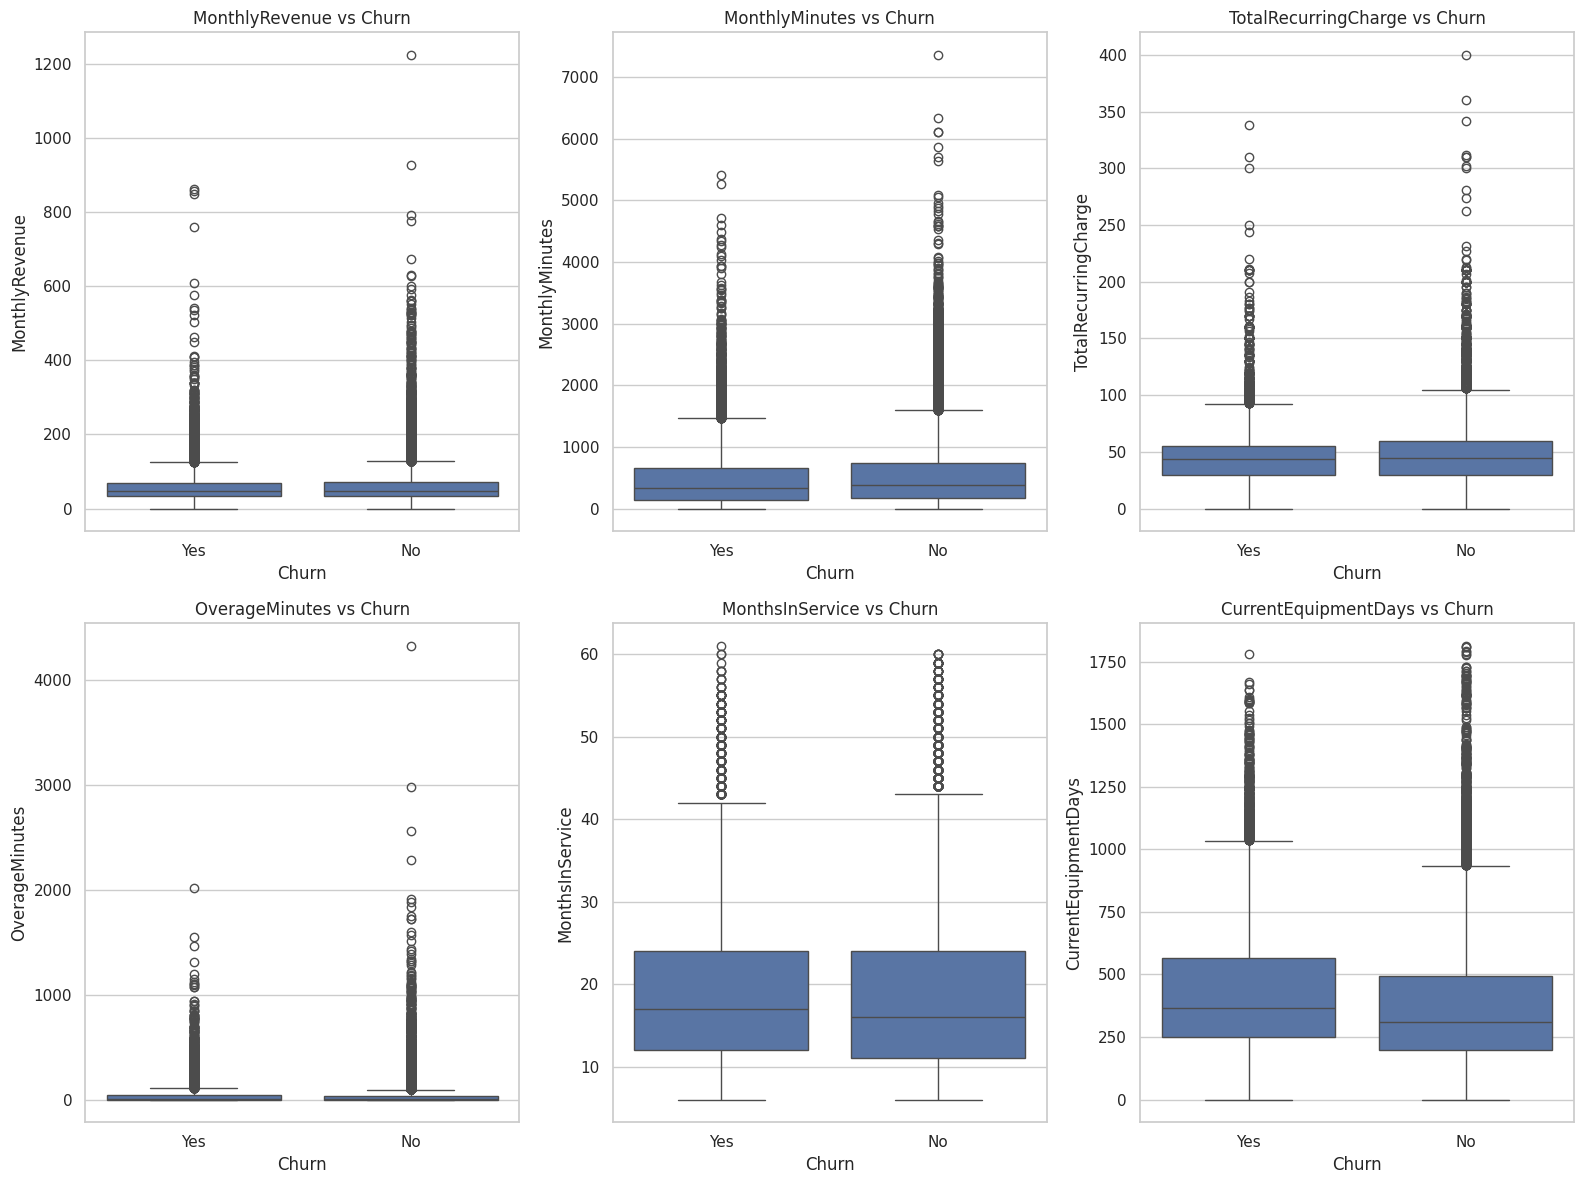

In [22]:
selected_features = [
    "MonthlyRevenue", "MonthlyMinutes", "TotalRecurringCharge",
    "OverageMinutes", "MonthsInService", "CurrentEquipmentDays"
]

plt.figure(figsize=(16, 12))
for i, col in enumerate(selected_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(data=df_clean, x="Churn", y=col)
    plt.title(f"{col} vs Churn")
    plt.xlabel("Churn")

plt.tight_layout()
plt.show()

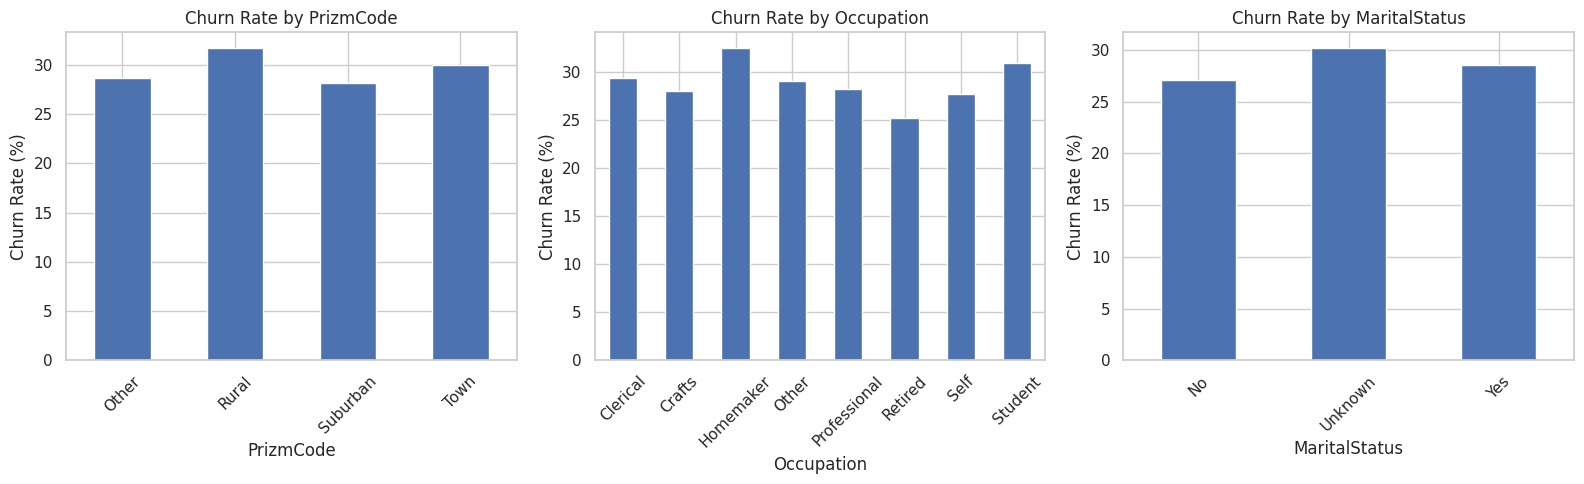

In [23]:
selected_categorical = ["PrizmCode", "Occupation", "MaritalStatus"]

plt.figure(figsize=(16, 5))
for i, col in enumerate(selected_categorical, 1):
    plt.subplot(1, 3, i)
    churn_rate = pd.crosstab(
        df_clean[col], df_clean["Churn"], normalize="index"
    ) * 100

    if "Yes" in churn_rate.columns:
        churn_rate["Yes"].plot(kind="bar")

    plt.title(f"Churn Rate by {col}")
    plt.ylabel("Churn Rate (%)")
    plt.xlabel(col)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

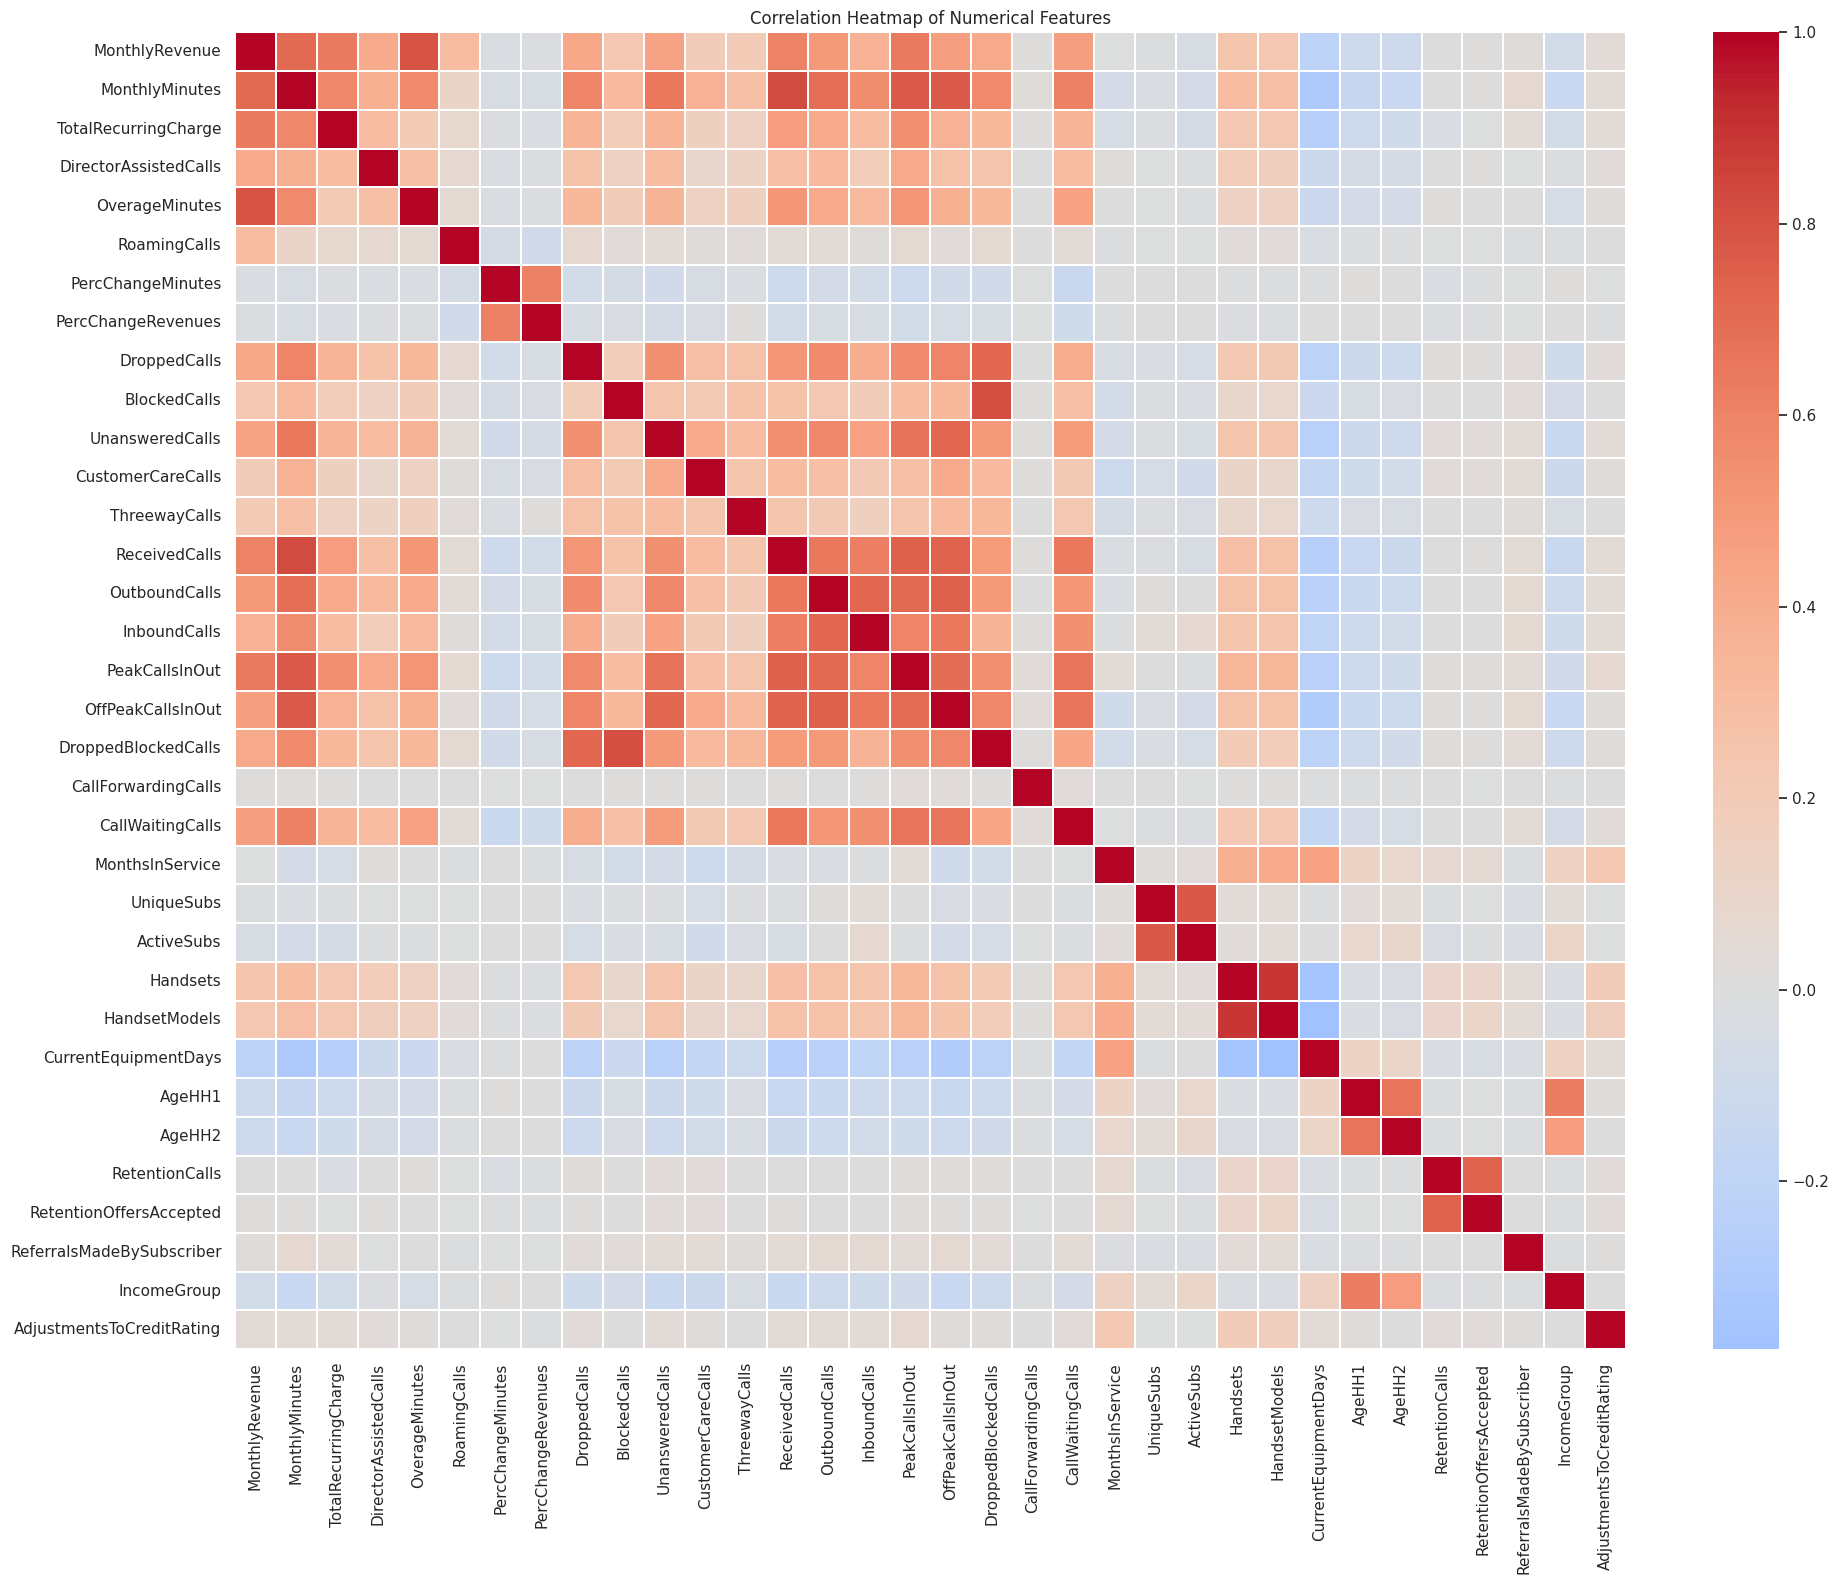

In [24]:
# Exclude the identifier from correlation analysis
correlation_data = df_clean.select_dtypes(include=np.number).drop(
    columns=["CustomerID"], errors="ignore"
)
correlation_matrix = correlation_data.corr()

plt.figure(figsize=(20, 16))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [25]:
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)
top_correlations = upper_triangle.stack().sort_values(ascending=False)

print("Top 15 Strongest Positive Correlations:")
print(top_correlations.head(15))

print("\nTop 15 Strongest Negative Correlations:")
print(top_correlations.tail(15))

Top 15 Strongest Positive Correlations:
Handsets         HandsetModels              0.887839
MonthlyMinutes   ReceivedCalls              0.828031
BlockedCalls     DroppedBlockedCalls        0.816328
MonthlyRevenue   OverageMinutes             0.787882
UniqueSubs       ActiveSubs                 0.775776
MonthlyMinutes   PeakCallsInOut             0.770326
                 OffPeakCallsInOut          0.763910
ReceivedCalls    PeakCallsInOut             0.746892
OutboundCalls    OffPeakCallsInOut          0.742311
ReceivedCalls    OffPeakCallsInOut          0.738185
RetentionCalls   RetentionOffersAccepted    0.734113
OutboundCalls    InboundCalls               0.724416
UnansweredCalls  OffPeakCallsInOut          0.719626
DroppedCalls     DroppedBlockedCalls        0.715420
MonthlyRevenue   MonthlyMinutes             0.712949
dtype: float64

Top 15 Strongest Negative Correlations:
CallWaitingCalls      CurrentEquipmentDays   -0.166358
CustomerCareCalls     CurrentEquipmentDays   -0.169064

## Part 5 - Data Preprocessing

In [26]:
# Create a separate modeling copy from the original dataset.
# Keep the original df unchanged; invalid negative values are treated as missing.
df_model = df.copy()

for col in ["CurrentEquipmentDays", "TotalRecurringCharge", "MonthlyRevenue"]:
    df_model.loc[df_model[col] < 0, col] = np.nan

print("Modeling dataset shape:", df_model.shape)
print("Missing values to be handled by the preprocessing pipeline:",
      df_model.isnull().sum().sum())

Modeling dataset shape: (51047, 58)
Missing values to be handled by the preprocessing pipeline: 3602


##Part 6 - Feature Engineering

In [27]:
# Explore potential features for feature engineering

feature_columns = [
    'MonthlyRevenue',
    'MonthlyMinutes',
    'TotalRecurringCharge',
    'OverageMinutes',
    'MonthsInService',
    'CurrentEquipmentDays',
    'RetentionCalls',
    'RetentionOffersAccepted'
]

print("Feature Statistics:")
display(df_model[feature_columns].describe().T)

Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
MonthlyRevenue,50888.0,58.838247,44.505960,0.0,33.61,48.46,71.07,1223.38
MonthlyMinutes,50891.0,525.653416,529.871063,0.0,158.00,366.00,723.00,7359.00
TotalRecurringCharge,50883.0,46.838276,23.841766,0.0,30.00,45.00,60.00,400.00
OverageMinutes,50891.0,40.027785,96.588076,0.0,0.00,3.00,41.00,4321.00
MonthsInService,51047.0,18.756264,9.800138,6.0,11.00,16.00,24.00,61.00
CurrentEquipmentDays,50970.0,381.116814,253.559703,0.0,205.00,330.00,516.00,1812.00
RetentionCalls,51047.0,0.037201,0.206483,0.0,0.00,0.00,0.00,4.00
RetentionOffersAccepted,51047.0,0.018277,0.142458,0.0,0.00,0.00,0.00,3.00


In [28]:
# Create new features
df_model_fe = df_model.copy()

# Average monthly usage
df_model_fe['AverageMonthlyUsage'] = (
    df_model_fe['MonthlyMinutes'] /
    df_model_fe['MonthsInService'].replace(0, np.nan)
)

# Overage ratio
df_model_fe['OverageRatio'] = (
    df_model_fe['OverageMinutes'] /
    (df_model_fe['MonthlyMinutes'] + 1)
)

# Retention engagement
df_model_fe['RetentionEngagement'] = (
    (df_model_fe['RetentionCalls'] > 0) |
    (df_model_fe['RetentionOffersAccepted'] > 0)
).astype(int)

print("New features created successfully!")

display(
    df_model_fe[
        ['AverageMonthlyUsage', 'OverageRatio', 'RetentionEngagement']
    ].describe().T
)

New features created successfully!


,count,mean,std,min,25%,50%,75%,max
AverageMonthlyUsage,50891.0,37.987003,47.499269,0.0,8.5,22.000000,48.857143,846.666667
OverageRatio,50891.0,0.061259,0.108741,0.0,0.0,0.007201,0.081260,0.991803
RetentionEngagement,51047.0,0.034184,0.181704,0.0,0.0,0.000000,0.000000,1.000000


In [29]:
from sklearn.model_selection import train_test_split

# Separate features and target (exclude CustomerID)
X = df_model_fe.drop(columns=['Churn', 'CustomerID'])
y = df_model_fe['Churn'].map({'No': 0, 'Yes': 1})

# Identify numerical and categorical features
numerical_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("CustomerID included:", 'CustomerID' in X.columns)

Training features: (40837, 59)
Testing features: (10210, 59)
Numerical features: 37
Categorical features: 22
CustomerID included: False


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='infrequent_if_exist',
        min_frequency=50
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [31]:
# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (40837, 287)
Testing data shape: (10210, 287)


In [32]:
import numpy as np
from scipy.sparse import issparse

def count_missing(data):
    if issparse(data):
        return np.isnan(data.data).sum()
    return np.isnan(data).sum()

print("Missing values in training:", count_missing(X_train_processed))
print("Missing values in testing:", count_missing(X_test_processed))

Missing values in training: 0
Missing values in testing: 0


In [33]:
print("CustomerID in X:", 'CustomerID' in X.columns)
print("CustomerID in X_train:", 'CustomerID' in X_train.columns)

CustomerID in X: False
CustomerID in X_train: False


##Part 7 - Model Building

###Logistic Regression

In [34]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

# Train the model
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Make predictions
y_pred = logistic_model.predict(X_test_processed)

# Predict probabilities for ROC-AUC
y_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.5784524975514201
Precision: 0.35669191919191917
Recall: 0.5761386811692726
F1-Score: 0.44060306732518845
ROC-AUC: 0.6103265686598396

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.58      0.66      7268
           1       0.36      0.58      0.44      2942

    accuracy                           0.58     10210
   macro avg       0.56      0.58      0.55     10210
weighted avg       0.65      0.58      0.60     10210


Confusion Matrix:
[[4211 3057]
 [1247 1695]]


###Decision Tree

In [36]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced',
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10
)

decision_tree_model.fit(X_train_processed, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

y_pred_tree = decision_tree_model.predict(X_test_processed)
y_prob_tree = decision_tree_model.predict_proba(X_test_processed)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1-Score:", f1_score(y_test, y_pred_tree))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tree))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

Accuracy: 0.5657198824681685
Precision: 0.35774218154080856
Recall: 0.637661454792658
F1-Score: 0.45834351331541656
ROC-AUC: 0.6162773584100911

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.54      0.64      7268
           1       0.36      0.64      0.46      2942

    accuracy                           0.57     10210
   macro avg       0.57      0.59      0.55     10210
weighted avg       0.66      0.57      0.59     10210


Confusion Matrix:
[[3900 3368]
 [1066 1876]]


###Random Forest

In [38]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_processed, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Make predictions
y_pred_rf = random_forest_model.predict(X_test_processed)

# Predict probabilities for ROC-AUC
y_prob_rf = random_forest_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.639177277179236
Precision: 0.4037363777893098
Recall: 0.5288919102651257
F1-Score: 0.4579164214243673
ROC-AUC: 0.6558406106389275

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.68      0.73      7268
           1       0.40      0.53      0.46      2942

    accuracy                           0.64     10210
   macro avg       0.59      0.61      0.59     10210
weighted avg       0.67      0.64      0.65     10210


Confusion Matrix:
[[4970 2298]
 [1386 1556]]


In [40]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [10, 20, 30],
    'min_samples_leaf': [5, 10, 15],
    'class_weight': ['balanced', 'balanced_subsample']
}

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=15,
    scoring='roc_auc',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_processed, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best Cross-Validation ROC-AUC:", random_search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_depth': None, 'class_weight': 'balanced_subsample'}
Best Cross-Validation ROC-AUC: 0.6667849137424723


In [41]:
best_rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_split=10,
    min_samples_leaf=5,
    max_depth=None,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

best_rf_model.fit(X_train_processed, y_train)

print("Best Random Forest model trained successfully!")

Best Random Forest model trained successfully!


In [42]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score,
    classification_report, confusion_matrix
)

y_pred_best = best_rf_model.predict(X_test_processed)
y_prob_best = best_rf_model.predict_proba(X_test_processed)[:, 1]

print("Best Random Forest Evaluation")
print("-" * 35)
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall:", recall_score(y_test, y_pred_best))
print("F1-Score:", f1_score(y_test, y_pred_best))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

Best Random Forest Evaluation
-----------------------------------
Accuracy: 0.6984329089128306
Precision: 0.4645261522527188
Recall: 0.30489462950373897
F1-Score: 0.3681510363225939
ROC-AUC: 0.662186514028136

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.86      0.80      7268
           1       0.46      0.30      0.37      2942

    accuracy                           0.70     10210
   macro avg       0.61      0.58      0.59     10210
weighted avg       0.67      0.70      0.68     10210

Confusion Matrix:
[[6234 1034]
 [2045  897]]


In [43]:
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Tuned Random Forest'
    ],
    'Accuracy': [
        0.57845, 0.56572, 0.63918, 0.69843
    ],
    'Precision': [
        0.35669, 0.35774, 0.40374, 0.46453
    ],
    'Recall': [
        0.57614, 0.63766, 0.52889, 0.30489
    ],
    'F1-Score': [
        0.44060, 0.45834, 0.45792, 0.36815
    ],
    'ROC-AUC': [
        0.61033, 0.61628, 0.65584, 0.66219
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.57845,0.35669,0.57614,0.44060,0.61033
1,Decision Tree,0.56572,0.35774,0.63766,0.45834,0.61628
2,Random Forest,0.63918,0.40374,0.52889,0.45792,0.65584
3,Tuned Random Forest,0.69843,0.46453,0.30489,0.36815,0.66219


###Final Model Selection

In [44]:
final_model = decision_tree_model

print("Final Model: Decision Tree")
print("Reason: Highest Recall among the tested models.")

Final Model: Decision Tree
Reason: Highest Recall among the tested models.


# Part 8 - Deployment

In [45]:
import joblib

joblib.dump(final_model, 'customer_churn_model.pkl')

print("Final model saved successfully!")

Final model saved successfully!


In [46]:
joblib.dump(preprocessor, 'customer_churn_preprocessor.pkl')

print("Preprocessor saved successfully!")

Preprocessor saved successfully!


In [47]:
import os

print("Model file exists:", os.path.exists('customer_churn_model.pkl'))
print("Preprocessor file exists:", os.path.exists('customer_churn_preprocessor.pkl'))

Model file exists: True
Preprocessor file exists: True


In [48]:
!pip install fastapi uvicorn nest-asyncio pyngrok streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 76.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 87.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [streamlit]


In [49]:
from fastapi import FastAPI

app = FastAPI(
    title="Customer Churn Prediction API",
    description="API for predicting customer churn using Machine Learning",
    version="1.0.0"
)

@app.get("/")
def home():
    return {
        "message": "Customer Churn Prediction API is running successfully!"
    }

In [50]:
import joblib

final_model = joblib.load('customer_churn_model.pkl')
preprocessor = joblib.load('customer_churn_preprocessor.pkl')

print("Model loaded successfully!")
print("Preprocessor loaded successfully!")

Model loaded successfully!
Preprocessor loaded successfully!


In [51]:
import pandas as pd
from fastapi import HTTPException
from typing import Dict, Any

@app.post("/predict")
def predict_churn(customer_data: Dict[str, Any]):

    try:
        # Convert customer data into a DataFrame
        input_data = pd.DataFrame([customer_data])

        # Create engineered features
        input_data['AverageMonthlyUsage'] = (
            input_data['MonthlyMinutes'] /
            input_data['MonthsInService'].replace(0, float('nan'))
        )

        input_data['OverageRatio'] = (
            input_data['OverageMinutes'] /
            (input_data['MonthlyMinutes'] + 1)
        )

        input_data['RetentionEngagement'] = (
            (input_data['RetentionCalls'] > 0) |
            (input_data['RetentionOffersAccepted'] > 0)
        ).astype(int)

        # Preprocess customer data
        processed_data = preprocessor.transform(input_data)

        # Make prediction
        prediction = final_model.predict(processed_data)[0]

        return {
            "prediction": int(prediction),
            "churn_status": "Yes" if prediction == 1 else "No"
        }

    except Exception as e:
        raise HTTPException(status_code=400, detail=str(e))

In [52]:
import nest_asyncio
import uvicorn
from threading import Thread

nest_asyncio.apply()

def run_api():
    uvicorn.run(app, host="0.0.0.0", port=8000)

api_thread = Thread(target=run_api, daemon=True)
api_thread.start()

print("FastAPI server started successfully!")

FastAPI server started successfully!


In [54]:
import socket
import requests

# Check whether port 8000 is listening
sock = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
sock.settimeout(2)

result = sock.connect_ex(("127.0.0.1", 8000))
sock.close()

print("Port 8000 status:", "OPEN" if result == 0 else "CLOSED")

if result == 0:
    try:
        response = requests.get(
            "http://127.0.0.1:8000/",
            timeout=5
        )
        print("Status Code:", response.status_code)
        print("Response:", response.json())
    except Exception as e:
        print("Request Error:", e)
else:
    print("FastAPI server is not reachable.")

Port 8000 status: OPEN
INFO:     127.0.0.1:34402 - "GET / HTTP/1.1" 200 OK
Status Code: 200
Response: {'message': 'Customer Churn Prediction API is running successfully!'}


In [55]:
# Get one customer from the original test data
sample_customer = X_test.iloc[[0]].copy()

# Convert customer data to dictionary
customer_data = sample_customer.iloc[0].to_dict()

# Send prediction request
response = requests.post(
    "http://127.0.0.1:8000/predict",
    json=customer_data
)

print("Status Code:", response.status_code)
print("Prediction Result:", response.json())

INFO:     127.0.0.1:44850 - "POST /predict HTTP/1.1" 200 OK
Status Code: 200
Prediction Result: {'prediction': 0, 'churn_status': 'No'}


In [56]:
import json
import numpy as np

engineered_features = [
    'AverageMonthlyUsage',
    'OverageRatio',
    'RetentionEngagement'
]

feature_config = {}

for col in X_train.columns:

    if col in engineered_features:
        continue

    if col in numerical_features:
        feature_config[col] = {
            "type": "numeric",
            "default": float(X_train[col].median())
        }

    else:
        options = X_train[col].dropna().unique().tolist()

        feature_config[col] = {
            "type": "categorical",
            "options": [str(x) for x in options],
            "default": str(X_train[col].mode()[0])
        }

with open("feature_config.json", "w") as f:
    json.dump(feature_config, f, indent=4)

print("Streamlit input configuration saved!")
print("Number of input features:", len(feature_config))

Streamlit input configuration saved!
Number of input features: 56


In [57]:

%%writefile app.py

import streamlit as st
import requests
import json

st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

API_URL = "http://127.0.0.1:8000/predict"

with open("feature_config.json", "r") as f:
    feature_config = json.load(f)

st.title("📊 Customer Churn Prediction System")
st.write("Predict whether a customer is likely to leave the company.")

st.divider()

customer_data = {}

with st.form("customer_form"):

    st.subheader("Customer Information")

    columns = st.columns(2)

    for i, (feature, config) in enumerate(feature_config.items()):

        with columns[i % 2]:

            if config["type"] == "numeric":
                customer_data[feature] = st.number_input(
                    feature,
                    value=float(config["default"])
                )

            else:
                customer_data[feature] = st.selectbox(
                    feature,
                    options=config["options"],
                    index=config["options"].index(config["default"])
                )

    submitted = st.form_submit_button("🔍 Predict Churn")

if submitted:

    try:
        response = requests.post(
            API_URL,
            json=customer_data,
            timeout=30
        )

        response.raise_for_status()
        result = response.json()

        st.subheader("Prediction Result")

        if result["churn_status"] == "Yes":
            st.error("⚠️ Customer is likely to Churn!")

        else:
            st.success("✅ Customer is likely to Stay!")

    except Exception as e:
        st.error(f"Prediction Error: {e}")

Writing app.py


In [58]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &

In [60]:
from pyngrok import ngrok

print("ngrok imported successfully!")

ngrok imported successfully!


In [62]:
from pyngrok import ngrok
from getpass import getpass

auth_token = getpass("Enter your ngrok Auth Token: ")
ngrok.set_auth_token(auth_token)

print("ngrok authentication configured successfully!")

Enter your ngrok Auth Token: ··········
ngrok authentication configured successfully!


In [63]:
streamlit_tunnel = ngrok.connect(8501)
print("Streamlit Public URL:", streamlit_tunnel)

Streamlit Public URL: NgrokTunnel: "https://uncapped-strode-glorify.ngrok-free.dev" -> "http://localhost:8501"


In [65]:
import requests

response = requests.get("http://127.0.0.1:8000/openapi.json")

print("Status:", response.status_code)

if response.status_code == 200:
    print("Available API Endpoints:")
    print(response.json()["paths"])

INFO:     127.0.0.1:46232 - "GET /openapi.json HTTP/1.1" 200 OK
Status: 200
Available API Endpoints:
{'/': {'get': {'summary': 'Home', 'operationId': 'home__get', 'responses': {'200': {'description': 'Successful Response', 'content': {'application/json': {'schema': {}}}}}}}, '/predict': {'post': {'summary': 'Predict Churn', 'operationId': 'predict_churn_predict_post', 'requestBody': {'content': {'application/json': {'schema': {'additionalProperties': True, 'type': 'object', 'title': 'Customer Data'}}}, 'required': True}, 'responses': {'200': {'description': 'Successful Response', 'content': {'application/json': {'schema': {}}}}, '422': {'description': 'Validation Error', 'content': {'application/json': {'schema': {'$ref': '#/components/schemas/HTTPValidationError'}}}}}}}}


In [66]:
# Select a customer from the test dataset
sample_index = 1

sample_customer = X_test.iloc[[sample_index]].copy()

# Actual customer status
actual_status = y_test.iloc[sample_index]

# Prepare customer data
customer_data = sample_customer.iloc[0].to_dict()

# Send prediction request to FastAPI
response = requests.post(
    "http://127.0.0.1:8000/predict",
    json=customer_data
)

prediction_result = response.json()

print("Actual Churn Status:",
      "Yes" if actual_status == 1 else "No")

print("Predicted Churn Status:",
      prediction_result["churn_status"])

INFO:     127.0.0.1:46238 - "POST /predict HTTP/1.1" 200 OK
Actual Churn Status: No
Predicted Churn Status: No


### Create a standalone FastAPI file for the GitHub repository

In [67]:
%%writefile api.py

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from typing import Dict, Any

app = FastAPI(
    title="Customer Churn Prediction API",
    description="API for predicting customer churn using Machine Learning",
    version="1.0.0"
)

final_model = joblib.load("customer_churn_model.pkl")
preprocessor = joblib.load("customer_churn_preprocessor.pkl")

@app.get("/")
def home():
    return {"message": "Customer Churn Prediction API is running successfully!"}

@app.post("/predict")
def predict_churn(customer_data: Dict[str, Any]):
    try:
        input_data = pd.DataFrame([customer_data])

        input_data["AverageMonthlyUsage"] = (
            input_data["MonthlyMinutes"] /
            input_data["MonthsInService"].replace(0, float("nan"))
        )
        input_data["OverageRatio"] = (
            input_data["OverageMinutes"] /
            (input_data["MonthlyMinutes"] + 1)
        )
        input_data["RetentionEngagement"] = (
            (input_data["RetentionCalls"] > 0) |
            (input_data["RetentionOffersAccepted"] > 0)
        ).astype(int)

        processed_data = preprocessor.transform(input_data)
        prediction = final_model.predict(processed_data)[0]

        return {
            "prediction": int(prediction),
            "churn_status": "Yes" if prediction == 1 else "No"
        }

    except Exception as e:
        raise HTTPException(status_code=400, detail=str(e))


Writing api.py


# Part 9 - GitHub

In [68]:
import os

os.makedirs("Customer_Churn_Project", exist_ok=True)

files_to_copy = [
    "app.py",
    "api.py",
    "feature_config.json",
    "customer_churn_model.pkl",
    "customer_churn_preprocessor.pkl"
]

import shutil

for file in files_to_copy:
    shutil.copy(file, "Customer_Churn_Project")

print("Project files organized successfully!")

print(os.listdir("Customer_Churn_Project"))

Project files organized successfully!
['customer_churn_preprocessor.pkl', 'customer_churn_model.pkl', 'app.py', 'api.py', 'feature_config.json']


In [69]:
%%writefile Customer_Churn_Project/requirements.txt

pandas
numpy
scikit-learn
joblib
fastapi
uvicorn
streamlit
requests

Writing Customer_Churn_Project/requirements.txt


In [70]:
%%writefile Customer_Churn_Project/README.md

# Customer Churn Prediction

## Project Overview
This project uses traditional Machine Learning to predict whether a telecom customer is likely to leave the company (Churn).

## Dataset
- Dataset: Cell2Cell Telecom Churn
- Number of records: 51,047
- Target variable: Churn

## Machine Learning Models
- Logistic Regression
- Decision Tree
- Random Forest
- Tuned Random Forest

## Final Model
Decision Tree was selected because it achieved the highest Recall among the tested models.

## Evaluation Metrics
Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

## Deployment
- FastAPI provides the prediction API.
- Streamlit provides the user interface.

## Project Files
- `Customer_Churn_Prediction_NTI_Project.ipynb`: project workflow.
- `api.py`: FastAPI application.
- `app.py`: Streamlit application.
- `feature_config.json`: input feature configuration.
- `customer_churn_model.pkl`: trained Decision Tree model.
- `customer_churn_preprocessor.pkl`: fitted preprocessing pipeline.
- `requirements.txt`: required Python libraries.

## How to Run

Install dependencies:

    pip install -r requirements.txt

Start the API in one terminal:

    uvicorn api:app --host 127.0.0.1 --port 8000

Start the Streamlit app in a second terminal:

    streamlit run app.py

Keep both processes running while using the application.


Writing Customer_Churn_Project/README.md


In [71]:
import os

project_files = os.listdir("Customer_Churn_Project")

for file in sorted(project_files):
    print("✅", file)

print("\nTotal files:", len(project_files))

✅ README.md
✅ api.py
✅ app.py
✅ customer_churn_model.pkl
✅ customer_churn_preprocessor.pkl
✅ feature_config.json
✅ requirements.txt

Total files: 7


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if file.endswith(".ipynb"):
            print("📓", os.path.join(root, file))

In [ ]:
import shutil
import os

source_path = "/content/drive/MyDrive/Colab Notebooks/Customer_Churn_Prediction_NTI.ipynb"

destination_path = "Customer_Churn_Project/Customer_Churn_Prediction_NTI_Project.ipynb"

shutil.copy2(source_path, destination_path)

print("Notebook copied successfully!")
print("File exists:", os.path.exists(destination_path))

In [ ]:
import os

project_path = "Customer_Churn_Project"

for file in sorted(os.listdir(project_path)):
    size = os.path.getsize(os.path.join(project_path, file)) / (1024 * 1024)
    print(f"✅ {file} — {size:.2f} MB")

print("\nTotal files:", len(os.listdir(project_path)))

In [ ]:
import shutil
import os

zip_path = shutil.make_archive(
    "Customer_Churn_Project",
    "zip",
    root_dir=".",
    base_dir="Customer_Churn_Project"
)

print("ZIP created successfully!")
print("File exists:", os.path.exists(zip_path))
print("ZIP size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

In [ ]:
from google.colab import files

files.download("Customer_Churn_Project.zip")